| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../10_OPTIMIZACION/10_3_Segundo_orden.ipynb) | [⏩](../11_MACHINE_LEARNING/11_1_Supervised_Learning.ipynb) |

# 10.4 Optimización restringida: factibilidad, Lagrange y KKT

**Objetivo del cuaderno.** incorporar restricciones físicas, resolver un problema geométrico y comprobar las condiciones de optimalidad

**Antes de empezar:** gradiente, convexidad y sistemas de ecuaciones. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)

## 1. Las restricciones forman parte del modelo

La forma estándar es

$$\min_x f(x)\quad\text{sujeto a}\quad h_j(x)=0,\quad g_i(x)\le0.$$

Igualdades expresan balances exactos; desigualdades expresan límites, positividad o recursos. Una restricción física incorrecta puede sesgar el resultado incluso si el solver funciona perfectamente. La factibilidad mide cuánto se cumplen las restricciones y es distinta de la optimalidad.

Una caja $l\le x\le u$ es una restricción común. Las restricciones no deben imponerse mediante recortar el resultado final de un ajuste arbitrario: esa operación normalmente no resuelve el problema restringido.

## 2. Igualdades y multiplicadores de Lagrange

Si minimizamos $f$ sobre $h(x)=0$, en un punto regular el gradiente de $f$ pertenece al espacio generado por los gradientes de las restricciones. Introducimos

$$\mathcal L(x,\lambda)=f(x)+\lambda^Th(x).$$

Las ecuaciones $\nabla_x\mathcal L=0$ y $h=0$ son necesarias bajo una condición de regularidad, como independencia de gradientes de las igualdades. Geométricamente, el gradiente objetivo no tiene componente de descenso en una dirección tangente factible.

## 3. Ejemplo: proyección sobre una recta

Queremos el punto más cercano a $c=(2,2)$ bajo $x_1+x_2=1$. Minimizamos $\tfrac12\|x-c\|^2$. La ecuación $x-c+\lambda(1,1)=0$ y la igualdad dan $\lambda=1.5$ y $x^*=(0.5,0.5)$.

Solución: [0.5 0.5] λ analítico: 1.5
Residuo estacionariedad: [0. 0.]


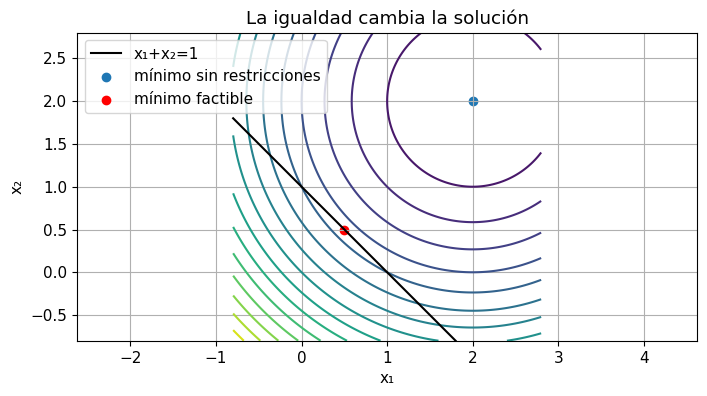

In [2]:
c0=np.array([2.,2.]);normal=np.ones(2)
def f(x):return 0.5*np.sum((x-c0)**2)
def jac(x):return x-c0
result=optimize.minimize(f,[0.,1.],jac=jac,method='SLSQP',constraints=[{'type':'eq','fun':lambda x:np.sum(x)-1,'jac':lambda x:normal}])
assert result.success
x_star=result.x;lagrange=(np.sum(c0)-1)/(normal@normal)
print('Solución:',x_star,'λ analítico:',lagrange)
print('Residuo estacionariedad:',jac(x_star)+lagrange*normal)
u,v=np.meshgrid(np.linspace(-0.8,2.8,180),np.linspace(-0.8,2.8,180))
plt.contour(u,v,0.5*((u-2)**2+(v-2)**2),levels=15)
line=np.linspace(-0.8,1.8,150);plt.plot(line,1-line,'k',label='x₁+x₂=1')
plt.scatter(*c0,label='mínimo sin restricciones');plt.scatter(*x_star,c='red',label='mínimo factible')
plt.xlabel('x₁');plt.ylabel('x₂');plt.title('La igualdad cambia la solución');plt.legend();plt.axis('equal');plt.show()

**Interpretación.** La recta toca una curva de nivel en el punto restringido. La solución sin restricciones es inviable. La distancia normal entre ambos puntos está determinada por el multiplicador; la componente tangente del gradiente en la solución es cero.

## 4. Desigualdades y condiciones KKT

Usando la convención $g_i(x)\le0$, definimos $\mathcal L=f+\lambda^Th+\mu^Tg$. Las condiciones de Karush–Kuhn–Tucker son:

1. Estacionariedad: $\nabla f+Dh^T\lambda+Dg^T\mu=0$.
2. Factibilidad primal: $h=0$ y $g\le0$.
3. Factibilidad dual: $\mu\ge0$.
4. Complementariedad: $\mu_i g_i=0$.

Una desigualdad inactiva ($g_i<0$) debe tener multiplicador cero. Una activa puede tener multiplicador positivo o cero. Las KKT requieren regularidad como condiciones necesarias; para un problema convexo, con igualdades afines, un punto que satisface KKT es un óptimo global.

## 5. Una desigualdad activa y una inactiva

Proyectamos $c=(2,0.2)$ sobre el simplex $x_1+x_2=1$, $x\ge0$. El resultado es $(1,0)$. Con $g_1=-x_1$ y $g_2=-x_2$, la primera desigualdad es inactiva y $\mu_1=0$. La estacionariedad da $\lambda=1$ y $\mu_2=0.8$.

In [3]:
target=np.array([2.,0.2])
f_simplex=lambda x:0.5*np.sum((x-target)**2)
r=optimize.minimize(f_simplex,[0.5,0.5],jac=lambda x:x-target,method='SLSQP',bounds=[(0,None),(0,None)],constraints=[{'type':'eq','fun':lambda x:x.sum()-1}],options={'ftol':1e-12})
x=r.x;lam=1.;mu=np.array([0.,0.8]);g=-x
print('Punto:',x,'éxito:',r.success)
print('Estacionariedad:',x-target+lam*np.ones(2)-mu)
print('Complementariedad:',mu*g)
assert r.success and np.allclose(x,[1,0],atol=1e-7)
assert np.linalg.norm(x-target+lam*np.ones(2)-mu)<1e-7

Punto: [1. 0.] éxito: True
Estacionariedad: [0. 0.]
Complementariedad: [-0. -0.]


## 6. Descenso de gradiente proyectado

Para un conjunto cerrado convexo $\mathcal F$, el paso es

$$x_{k+1}=\Pi_{\mathcal F}(x_k-\eta\nabla f(x_k)).$$

La proyección devuelve el punto factible más cercano en norma euclídea. Para una caja equivale a `clip`; para un simplex requiere un umbral común. En dos dimensiones parametrizamos el simplex por $(s,1-s)$ y resolvemos su proyección con $s=\operatorname{clip}((z_1-z_2+1)/2,0,1)$.

A diferencia de recortar al final, cada paso considera la geometría factible. Su punto fijo expresa una condición de optimalidad sobre el conjunto.

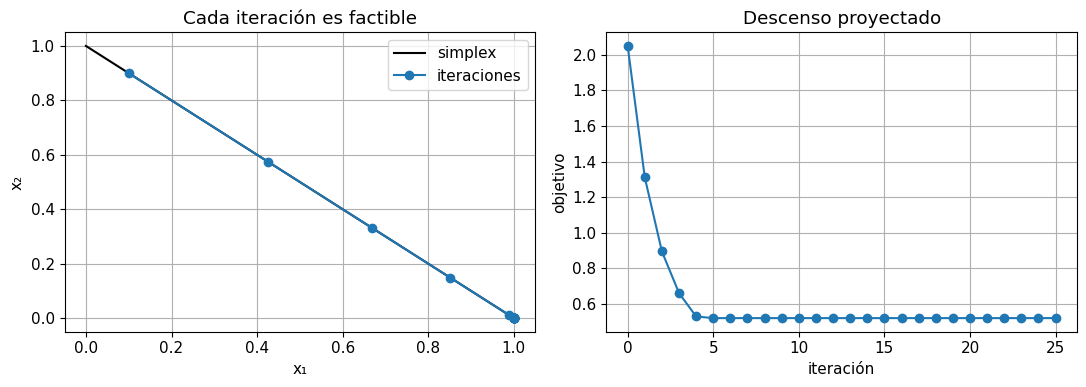

In [4]:
def project_simplex2(z):
    s=np.clip((z[0]-z[1]+1)/2,0,1)
    return np.array([s,1-s])
point=np.array([0.1,0.9]);trajectory=[point.copy()]
for _ in range(25):
    point=project_simplex2(point-0.25*(point-target));trajectory.append(point.copy())
trajectory=np.array(trajectory)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot([0,1],[1,0],'k',label='simplex');ax[0].plot(trajectory[:,0],trajectory[:,1],'o-',label='iteraciones')
ax[0].set(xlabel='x₁',ylabel='x₂',title='Cada iteración es factible');ax[0].legend()
ax[1].plot([f_simplex(z) for z in trajectory],'o-');ax[1].set(xlabel='iteración',ylabel='objetivo',title='Descenso proyectado')
plt.tight_layout();plt.show()
assert np.allclose(trajectory.sum(axis=1),1)
assert np.min(trajectory)>=0

## 7. Penalizaciones: aproximar una igualdad

Una penalización cuadrática usa $f_\rho(x)=f(x)+\frac\rho2\|h(x)\|^2$. Con $\rho$ finito generalmente no se cumple $h=0$ exactamente. Hacer $\rho$ enorme reduce violación pero empeora condicionamiento: la curvatura normal a la restricción domina.

El Lagrangiano aumentado combina $f+\lambda^Th+\frac\rho2\|h\|^2$ con una actualización de $\lambda$. Permite controlar factibilidad sin depender solo de penalizaciones gigantes. En PINNs las condiciones de borde pueden imponerse suavemente en la pérdida o exactamente mediante una parametrización; sus consecuencias numéricas difieren.

## 8. La tensión entre violación y condicionamiento

En la proyección sobre $x_1+x_2=1$, la solución penalizada se obtiene de $(I+\rho aa^T)x=c+\rho a$, con $a=(1,1)$. Sus autovalores son 1 y $1+2\rho$: el número de condición crece linealmente con la penalización.

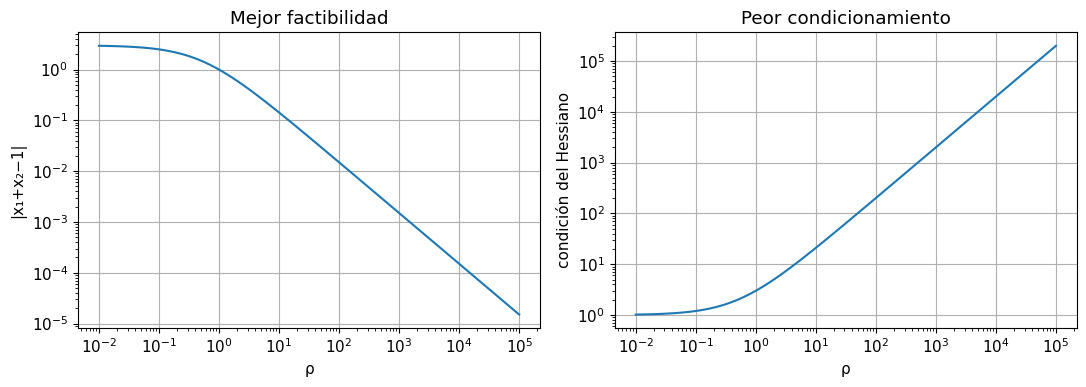

In [5]:
rho_values=np.logspace(-2,5,80);violations=[];conditions=[]
for rho in rho_values:
    H=np.eye(2)+rho*np.outer(normal,normal)
    sol=np.linalg.solve(H,c0+rho*normal)
    violations.append(abs(sol.sum()-1));conditions.append(np.linalg.cond(H))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].loglog(rho_values,violations);ax[0].set(xlabel='ρ',ylabel='|x₁+x₂−1|',title='Mejor factibilidad')
ax[1].loglog(rho_values,conditions);ax[1].set(xlabel='ρ',ylabel='condición del Hessiano',title='Peor condicionamiento')
plt.tight_layout();plt.show()

**Interpretación.** La figura muestra dos efectos simultáneos de aumentar $\rho$. Conseguir una violación pequeña no es gratuito: exige resolver un problema más anisótropo. El método de restricciones explícitas puede ser preferible cuando el balance debe cumplirse con una tolerancia estricta.

## 9. Programación lineal y límites de recursos

Un problema lineal tiene objetivo $c^Tx$ y restricciones afines. Un óptimo puede estar en un vértice, haber varios óptimos o no existir por falta de acotación. Una formulación física de producción usa unidades consistentes en cada fila de recursos. `linprog` minimiza; para maximizar beneficio usamos el negativo.

In [6]:
benefit=np.array([3.,2.])
resource=np.array([[1.,1.],[2.,1.]])
capacity=np.array([4.,6.])
lp=optimize.linprog(-benefit,A_ub=resource,b_ub=capacity,bounds=[(0,None),(0,None)],method='highs')
assert lp.success
print('Producción óptima:',lp.x,'Beneficio:',-lp.fun)
print('Holguras de recursos:',capacity-resource@lp.x)
assert np.all(resource@lp.x<=capacity+1e-8)

Producción óptima: [2. 2.] Beneficio: 10.0
Holguras de recursos: [0. 0.]


## 10. Diagnóstico y conexión científica

Registra por separado valor objetivo, violación de igualdades, violación de desigualdades, restricciones activas y residuo de estacionariedad. Una tolerancia objetivo pequeña no asegura un balance conservativo exacto. Positividad, conservación de masa y límites termodinámicos deben formar parte de la formulación y de la validación.

En un modelo aprendido, imponer una suma de fracciones igual a uno puede hacerse con variables reducidas o una parametrización softmax. Esta última garantiza interior positivo pero no permite ceros exactos con parámetros finitos. Elegir la representación cambia el espacio de soluciones alcanzables.

## 11. Multiplicadores y sensibilidad al recurso

Considera una igualdad escrita $h(x)-b=0$. Si el óptimo y sus multiplicadores varían suavemente con $b$, la derivada del valor óptimo es $d f^*/db=-\lambda$ bajo nuestra convención de Lagrangiano. El signo depende de cómo escribimos la restricción: invertirla cambia el signo del multiplicador, pero no la sensibilidad física.

En la proyección de $(2,2)$ sobre $x_1+x_2=b$, el valor óptimo es $(4-b)^2/4$ y $\lambda=(4-b)/2$. Para $b=1$, aumentar ligeramente el lado derecho reduce el valor objetivo a razón aproximada de 1.5 por unidad. Esta interpretación local deja de ser suave si cambia el conjunto activo o se pierde regularidad.

En recursos de producción, una restricción activa con multiplicador relevante puede señalar qué capacidad conviene ampliar marginalmente. La interpretación se limita al intervalo donde permanecen vigentes las mismas condiciones; no autoriza extrapolar linealmente el beneficio hasta capacidades arbitrarias. Para modelos físicos, sensibilidad del óptimo no equivale a causalidad de un parámetro en datos observacionales.

## Síntesis y conexión con Scientific Machine Learning

Las restricciones definen qué soluciones son científicamente aceptables. Lagrange y KKT explican la geometría; proyecciones, penalizaciones y métodos explícitos ofrecen caminos numéricos diferentes. En SciML los balances y las condiciones de borde deben verificarse además de la pérdida.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../10_OPTIMIZACION/10_3_Segundo_orden.ipynb) | [⏩](../11_MACHINE_LEARNING/11_1_Supervised_Learning.ipynb) |